# 03 - Engenharia de features e modelagem

## Baseline de referência (v2)
Modelo `HistGradientBoostingClassifier` com 17 features disponíveis na submissão
(`tipo_contrato`, `valor_credito`, `valor_bem`, `valor_parcela` e o cadastral, sem `sexo`),
split OOT 80/20 com embargo de 360 dias e teste de 20.822 contratos.

| Métrica (teste completo, com embargo) | v1 (36 features) | v2 (17 features) |
|---|---|---|
| AUC | 0,584 | 0,556 |
| KS | 0,134 | 0,093 |

Walk-forward v2 (folds 2 a 4): AUC 0,575 / 0,612 / 0,582.

**Por que é a referência:** o v1 usava colunas que não existem na submissão
(`tipo_cliente`, `indicador_seguro_contratado`, condições do contrato), então não é
reproduzível em produção. O v2 mede o desempenho real do que estará disponível na
submissão. Toda feature nova será comparada ao v2, no mesmo teste e com os mesmos parâmetros.

In [1]:
import importlib
import sys
from pathlib import Path
sys.path.append("..")

import src.functions as fn #Funcoes criadas no projeto
importlib.reload(fn)

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

In [2]:
COL_DATA, COL_CLIENTE, COL_TARGET = "data_decisao", "id_cliente", "OVER60MOB12"
PROP_TREINO, EMBARGO_DIAS, N_FOLDS = 0.80, 360, 4
MIN_MAUS_TREINO_FOLD, MIN_MAUS_VAL_FOLD = 300, 100

# Valores esperados (validação de reprodutibilidade)
N_TREINO_ESPERADO, N_SEM_ROTULO_ESPERADO = 104157, 107787

DIR_PROCESSADOS = Path("../dados/processados")
ARQUIVOS = {
    "abt_completa": "abt_completa.parquet",
    "abt_submissao": "abt_submissao.parquet",
}

for arquivo in ARQUIVOS.values():
    assert (DIR_PROCESSADOS / arquivo).exists(), f"Arquivo não encontrado: {DIR_PROCESSADOS / arquivo}"

base_completa = pd.read_parquet(DIR_PROCESSADOS / ARQUIVOS["abt_completa"])
base_submissao = pd.read_parquet(DIR_PROCESSADOS / ARQUIVOS["abt_submissao"])

# Referência temporal única: data_decisao no treino, data_solicitacao na submissão
base_completa["data_ref"] = base_completa[COL_DATA]
base_submissao["data_ref"] = base_submissao["data_solicitacao"]

# Treino: validação estrita
assert base_completa["data_ref"].notna().all(), "data_ref nula em base_completa"

# Submissão: diagnóstico (não interrompe a execução)
n_nulos_sub = int(base_submissao["data_ref"].isna().sum())
print(f"base_submissao: data_ref nula em {n_nulos_sub} de {len(base_submissao)} "
      f"({n_nulos_sub / len(base_submissao):.4%})")
print("dtype data_solicitacao:", base_submissao["data_solicitacao"].dtype)
colunas_data_flag = [c for c in base_submissao.columns if "data" in c or "flag" in c]
print("colunas de data/flag:", colunas_data_flag)
print(base_submissao.loc[base_submissao["data_ref"].isna(), colunas_data_flag].head(5))

# Separação: rotulados (treino) e sem rótulo (somente Reject Inference no treino)
mask_rotulado = base_completa[COL_TARGET].notna()
base_treino = base_completa.loc[mask_rotulado].copy()
base_sem_rotulo = base_completa.loc[~mask_rotulado].copy()

assert len(base_treino) == N_TREINO_ESPERADO, "base_treino com tamanho inesperado"
assert len(base_sem_rotulo) == N_SEM_ROTULO_ESPERADO, "base_sem_rotulo com tamanho inesperado"

print("base_completa:", base_completa.shape)
print("base_treino:", base_treino.shape, "| base_sem_rotulo:", base_sem_rotulo.shape)
print("base_submissao:", base_submissao.shape, "| data_ref nula:", int(base_submissao["data_ref"].isna().sum()))

base_submissao: data_ref nula em 51 de 50400 (0.1012%)
dtype data_solicitacao: datetime64[us]
colunas de data/flag: ['data_solicitacao', 'data_invalida', 'data_nascimento', 'data_nascimento_invalida', 'data_ref']
     data_solicitacao data_invalida data_nascimento  data_nascimento_invalida  \
1713              NaT          True      2001-03-04                     False   
3132              NaT          True      1974-12-21                     False   
4396              NaT          True      1984-11-23                     False   
6004              NaT          True      1989-06-22                     False   
6605              NaT          True      1985-02-03                     False   

     data_ref  
1713      NaT  
3132      NaT  
4396      NaT  
6004      NaT  
6605      NaT  
base_completa: (211944, 52)
base_treino: (104157, 52) | base_sem_rotulo: (107787, 52)
base_submissao: (50400, 23) | data_ref nula: 51


In [3]:
# ============================================================
# Split OOT e baseline v2 (17 features disponíveis na submissão)
# ============================================================
# Features comuns entre treino e submissão, sem chaves, target, datas e apoio
APOIO_V2 = {
    COL_CLIENTE, "id_contrato", COL_TARGET, COL_DATA, "data_ref",
    "data_solicitacao", "data_nascimento", "data_invalida",
    "data_nascimento_invalida",
}
FEATURES_V2 = [
    c for c in base_treino.columns
    if c in base_submissao.columns and c not in APOIO_V2
]
print(f"FEATURES_V2: {len(FEATURES_V2)} colunas")
print(FEATURES_V2)
assert len(FEATURES_V2) == 17, "FEATURES_V2 deve ter 17 colunas"

# Split temporal: com e sem embargo, teste idêntico nos dois cenários
tr_sem, teste, data_corte = fn.dividir_oot(base_treino, COL_DATA, PROP_TREINO, 0)
tr_com, _, _ = fn.dividir_oot(base_treino, COL_DATA, PROP_TREINO, EMBARGO_DIAS)
print("data_corte:", data_corte)
print("tr_sem:", len(tr_sem), "| tr_com:", len(tr_com), "| teste:", len(teste))

# Baseline v2: deve reproduzir AUC 0,556 e KS 0,093 (com embargo, completo)
res_v2 = fn.avaliar_oot(
    {"sem_embargo": tr_sem, "com_embargo": tr_com},
    teste, FEATURES_V2, COL_TARGET, COL_CLIENTE,
)
display(res_v2)

wf_v2 = fn.walk_forward(
    tr_com, FEATURES_V2, COL_DATA, COL_CLIENTE, COL_TARGET,
    N_FOLDS, EMBARGO_DIAS, MIN_MAUS_TREINO_FOLD, MIN_MAUS_VAL_FOLD,
)
display(wf_v2)

FEATURES_V2: 17 colunas
['tipo_contrato', 'valor_credito', 'valor_bem', 'valor_parcela', 'qtd_filhos', 'qtd_membros_familia', 'renda_anual', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel', 'nota_regiao_cliente', 'nota_regiao_cliente_cidade']
data_corte: 2023-06-06 00:00:00
tr_sem: 83335 | tr_com: 59535 | teste: 20822


,cenario,recorte,n,taxa_maus,auc,ks
0,sem_embargo,completo,20822,0.078667,0.567505,0.112604
1,sem_embargo,novos,6041,0.129780,0.536129,0.070117
2,sem_embargo,recorrentes,14781,0.057777,0.572694,0.132593
3,sem_embargo,treino (in-sample),83335,0.069695,0.705587,0.299345
4,com_embargo,completo,20822,0.078667,0.555977,0.092856
5,com_embargo,novos,8765,0.112151,0.541274,0.066538
6,com_embargo,recorrentes,12057,0.054325,0.574411,0.149623
7,com_embargo,treino (in-sample),59535,0.071790,0.712512,0.304535


,fold,val_inicio,val_fim,n_treino,maus_treino,n_val,maus_val,auc,ks,features_removidas,status
0,1,2018-07-02,2019-08-29,1842,116,11894,957,NaN,NaN,,ignorado: maus insuficientes
1,2,2019-08-29,2020-10-17,9740,684,11911,965,0.574617,0.135236,,ok
2,3,2020-10-17,2021-09-19,18058,1454,11903,841,0.612181,0.179185,,ok
3,4,2021-09-19,2022-06-11,25574,2186,11904,808,0.581797,0.131333,,ok


In [13]:
## Criação de features Grupo A (sem histórico)

In [4]:
# ============================================================
# Grupo A: features sem histórico (idade e razões)
# ============================================================
importlib.reload(fn)

FEATURES_A_NOVAS = [
    "idade_anos", "razao_credito_parcela", "razao_credito_bem",
    "razao_credito_renda", "razao_parcela_renda",
]

base_treino = fn.criar_features_grupo_a(base_treino)
base_submissao = fn.criar_features_grupo_a(base_submissao)

# Validações: sem infinitos e nulos esperados
for nome, df in {"treino": base_treino, "submissao": base_submissao}.items():
    print(f"\n{nome}")
    print(df[FEATURES_A_NOVAS].describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]])
    print("nulos:", df[FEATURES_A_NOVAS].isna().sum().to_dict())
    assert not np.isinf(df[FEATURES_A_NOVAS].to_numpy(dtype="float64")).any(), "infinito em features"


treino
                             min         1%        50%        99%         max
idade_anos             18.004107  19.964408  40.355921  64.286954   67.920602
razao_credito_parcela   2.450693   3.898304   9.494212  36.219710  200.000000
razao_credito_bem       0.710710   0.805556   1.000000   1.206250    1.392618
razao_credito_renda     0.000177   0.024618   0.609271   8.800000   38.139083
razao_parcela_renda     0.000006   0.001378   0.064693   0.525867    5.564369
nulos: {'idade_anos': 837, 'razao_credito_parcela': 3895, 'razao_credito_bem': 7072, 'razao_credito_renda': 4235, 'razao_parcela_renda': 745}

submissao
                             min         1%        50%        99%          max
idade_anos             20.114990  21.930212  43.307324  67.260753    68.993840
razao_credito_parcela   4.068335   6.189756  20.000000  43.780493  3792.667509
razao_credito_bem       0.300000   0.819481   1.105603   1.475200   152.800000
razao_credito_renda     0.001437   0.341918   2.831360 

In [5]:
# ============================================================
# Diagnóstico do Grupo A (sem métricas de modelo)
# ============================================================
IDADE_MIN, IDADE_MAX = 18, 100
LIM_RAZAO_EXTREMA = {"razao_credito_parcela": 100, "razao_credito_bem": 2, "razao_credito_renda": 50}

for nome, df in {"treino": base_treino, "submissao": base_submissao}.items():
    idade = df["idade_anos"]
    fora_idade = idade.notna() & ((idade < IDADE_MIN) | (idade > IDADE_MAX))
    print(f"\n{nome}")
    print("idade fora de [18, 100]:", int(fora_idade.sum()))
    print("idade negativa:", int((idade < 0).sum()))
    print("valor_credito <= 0:", int((df["valor_credito"] <= 0).sum()))
    print("valor_bem <= 0:", int((df["valor_bem"] <= 0).sum()))
    print("valor_parcela <= 0:", int((df["valor_parcela"] <= 0).sum()))
    for col, lim in LIM_RAZAO_EXTREMA.items():
        print(f"{col} > {lim}:", int((df[col] > lim).sum()))

# Amostra de linhas extremas na submissão
extremos = base_submissao["razao_credito_bem"] > LIM_RAZAO_EXTREMA["razao_credito_bem"]
print(base_submissao.loc[extremos, ["valor_credito", "valor_bem", "valor_parcela", "renda_anual", "data_ref", "data_nascimento"]].head(10))


treino
idade fora de [18, 100]: 0
idade negativa: 0
valor_credito <= 0: 3729
valor_bem <= 0: 87
valor_parcela <= 0: 218
razao_credito_parcela > 100: 3
razao_credito_bem > 2: 0
razao_credito_renda > 50: 0

submissao
idade fora de [18, 100]: 0
idade negativa: 0
valor_credito <= 0: 0
valor_bem <= 0: 0
valor_parcela <= 0: 67
razao_credito_parcela > 100: 67
razao_credito_bem > 2: 132
razao_credito_renda > 50: 66
      valor_credito  valor_bem  valor_parcela  renda_anual   data_ref  \
607      27000000.0   270000.0        13500.0     180000.0 2025-02-23   
1293       942300.0   329805.0        34749.0     189000.0 2025-02-06   
1331       270000.0    94500.0        13500.0     180000.0 2025-02-20   
1360       180000.0    63000.0         9000.0      90000.0 2025-02-13   
1378     45000000.0   450000.0        22018.5     225000.0 2025-02-16   
1412     49049550.0   454500.0        29335.5     112500.0 2025-02-18   
1997       630000.0   220500.0        34308.0     238500.0 2025-02-17   
2423

In [6]:
# ============================================================
# Diagnóstico para definição de políticas e tratamento
# ============================================================
# 1) Distribuição da razão crédito/bem na submissão: separar grupo 1 e grupo 2
r = base_submissao["razao_credito_bem"]
faixas_razao = pd.cut(r, bins=[0, 1.5, 2, 3, 10, 50, np.inf], right=False)
print(faixas_razao.value_counts(sort=False, dropna=False))

# Grupo 2: razão ~ 2,857 (bem = 35% do crédito)
grupo2 = r.between(2.8, 2.9)
print("razão ~2,857:", int(grupo2.sum()))

# Grupo 1: razão do crédito/100 vs bem, deve voltar para faixa plausível
grupo1 = r > 10
razao_corrigida = (base_submissao["valor_credito"] / 100) / base_submissao["valor_bem"]
print("grupo 1:", int(grupo1.sum()))
print(razao_corrigida[grupo1].describe(percentiles=[.05, .5, .95]))

# 2) Treino: crédito <= 0
cred0 = base_treino["valor_credito"] <= 0
print("\ncrédito <= 0 no treino:", int(cred0.sum()))
print("taxa de maus (crédito <= 0):", round(base_treino.loc[cred0, COL_TARGET].mean(), 4))
print("taxa de maus (crédito > 0): ", round(base_treino.loc[~cred0, COL_TARGET].mean(), 4))
print(base_treino.loc[cred0].filter(regex="status|tipo_contrato|data_decisao").head())

# 3) Impacto de cada política candidata na submissão
politicas = {
    "razao_credito_bem > 10": r > 10,
    "razao_credito_bem > 2 (inclui grupo 2)": r > 2,
    "valor_parcela <= 0": base_submissao["valor_parcela"] <= 0,
    "renda_anual <= 0 ou nula": ~(base_submissao["renda_anual"] > 0),
}
for nome, m in politicas.items():
    print(f"{nome}: {int(m.sum())} ({m.mean():.3%})")

razao_credito_bem
[0.0, 1.5)      47513
[1.5, 2.0)        291
[2.0, 3.0)         73
[3.0, 10.0)         0
[10.0, 50.0)        0
[50.0, inf)        63
NaN              2460
Name: count, dtype: int64
razão ~2,857: 67
grupo 1: 63
count    63.000000
mean      1.109808
std       0.127682
min       0.844915
5%        1.000000
50%       1.080386
95%       1.316812
max       1.528000
dtype: float64

crédito <= 0 no treino: 3729
taxa de maus (crédito <= 0): 0.0461
taxa de maus (crédito > 0):  0.0724
                tipo_contrato status_contrato data_decisao
10     emprestimo em dinheiro        aprovado   2022-09-15
192  financiamento de consumo        aprovado   2021-10-23
221  financiamento de consumo        aprovado   2021-11-25
232    emprestimo em dinheiro        aprovado   2022-12-26
239    emprestimo em dinheiro        aprovado   2018-10-23
razao_credito_bem > 10: 63 (0.125%)
razao_credito_bem > 2 (inclui grupo 2): 132 (0.262%)
valor_parcela <= 0: 67 (0.133%)
renda_anual <= 0 ou nula: 232

In [7]:
# ============================================================
# Diagnóstico: grupo razão ~2,857, parcela <= 0 e crédito <= 0
# ============================================================
sub = base_submissao
mask_parc0 = sub["valor_parcela"] <= 0
mask_r2 = (sub["razao_credito_bem"] > 2) & (sub["razao_credito_bem"] < 3)
print("parcela<=0 e razão em [2,3):", int((mask_parc0 & mask_r2).sum()), "de", int(mask_parc0.sum()))
print(sub.loc[mask_parc0, "tipo_contrato"].value_counts(dropna=False))

trn = base_treino
mask_parc0_t = trn["valor_parcela"] <= 0
print("\ntreino parcela<=0:", int(mask_parc0_t.sum()),
      "| taxa de maus:", round(float(trn.loc[mask_parc0_t, COL_TARGET].mean()), 4))
print(trn.loc[mask_parc0_t, "tipo_contrato"].value_counts(dropna=False))

mask_c0 = trn["valor_credito"] <= 0
print("\ntreino crédito<=0 por tipo_contrato:")
print(trn.loc[mask_c0, "tipo_contrato"].value_counts(dropna=False))
print("valor_bem nos crédito<=0:", trn.loc[mask_c0, "valor_bem"].describe()[["count", "min", "50%", "max"]].to_dict())
print("valor_parcela nos crédito<=0:", trn.loc[mask_c0, "valor_parcela"].describe()[["count", "min", "50%", "max"]].to_dict())

parcela<=0 e razão em [2,3): 0 de 67
tipo_contrato
financiamento de consumo    29
emprestimo em dinheiro      21
credito rotativo            17
Name: count, dtype: int64

treino parcela<=0: 218 | taxa de maus: 0.0688
tipo_contrato
emprestimo em dinheiro      88
financiamento de consumo    80
credito rotativo            50
Name: count, dtype: int64

treino crédito<=0 por tipo_contrato:
tipo_contrato
financiamento de consumo    1406
emprestimo em dinheiro      1397
credito rotativo             926
Name: count, dtype: int64
valor_bem nos crédito<=0: {'count': 87.0, 'min': 0.0, '50%': 0.0, 'max': 0.0}
valor_parcela nos crédito<=0: {'count': 3729.0, 'min': 0.0, '50%': 9000.0, 'max': 67500.0}


In [8]:
# ============================================================
# Diagnóstico: razão crédito/bem acima do suporte do treino
# ============================================================
MAX_RAZAO_TREINO = base_treino["razao_credito_bem"].max()
sub = base_submissao
acima = (sub["razao_credito_bem"] > MAX_RAZAO_TREINO) & (sub["razao_credito_bem"] <= 10)
print("máx. razão no treino:", round(MAX_RAZAO_TREINO, 3), "| linhas acima na submissão:", int(acima.sum()))

# Valores mais frequentes da razão (revela padrões sistemáticos)
print(sub.loc[acima, "razao_credito_bem"].round(3).value_counts().head(8))

# Tipo de contrato nas linhas acima do suporte vs. na submissão inteira
print(pd.crosstab(sub["tipo_contrato"], acima, normalize="index").round(4))

# Treino: distribuição da razão por tipo de contrato (somente crédito > 0)
trn_ok = base_treino["valor_credito"] > 0
print(base_treino.loc[trn_ok].groupby("tipo_contrato")["razao_credito_bem"]
      .describe(percentiles=[.01, .99])[["count", "min", "1%", "99%", "max"]])

# Amostra das linhas acima do suporte
print(sub.loc[acima, ["tipo_contrato", "valor_credito", "valor_bem", "valor_parcela", "razao_credito_bem"]].head(8))

máx. razão no treino: 1.393 | linhas acima na submissão: 2300
razao_credito_bem
1.396    1117
1.422     643
1.528     259
1.475     123
2.857      67
1.449      23
1.429      17
1.660      14
Name: count, dtype: int64
razao_credito_bem          False   True 
tipo_contrato                           
credito rotativo          0.9567  0.0433
emprestimo em dinheiro    0.9550  0.0450
financiamento de consumo  0.9521  0.0479
                            count       min        1%       99%       max
tipo_contrato                                                            
credito rotativo          24521.0  0.710710  0.805307  1.209917  1.381581
emprestimo em dinheiro    36788.0  0.711090  0.807279  1.206096  1.392618
financiamento de consumo  35776.0  0.713467  0.804284  1.204359  1.386113
                tipo_contrato  valor_credito  valor_bem  valor_parcela  \
1            credito rotativo       979992.0   702000.0        27076.5   
19     emprestimo em dinheiro      1256400.0   900000.0    

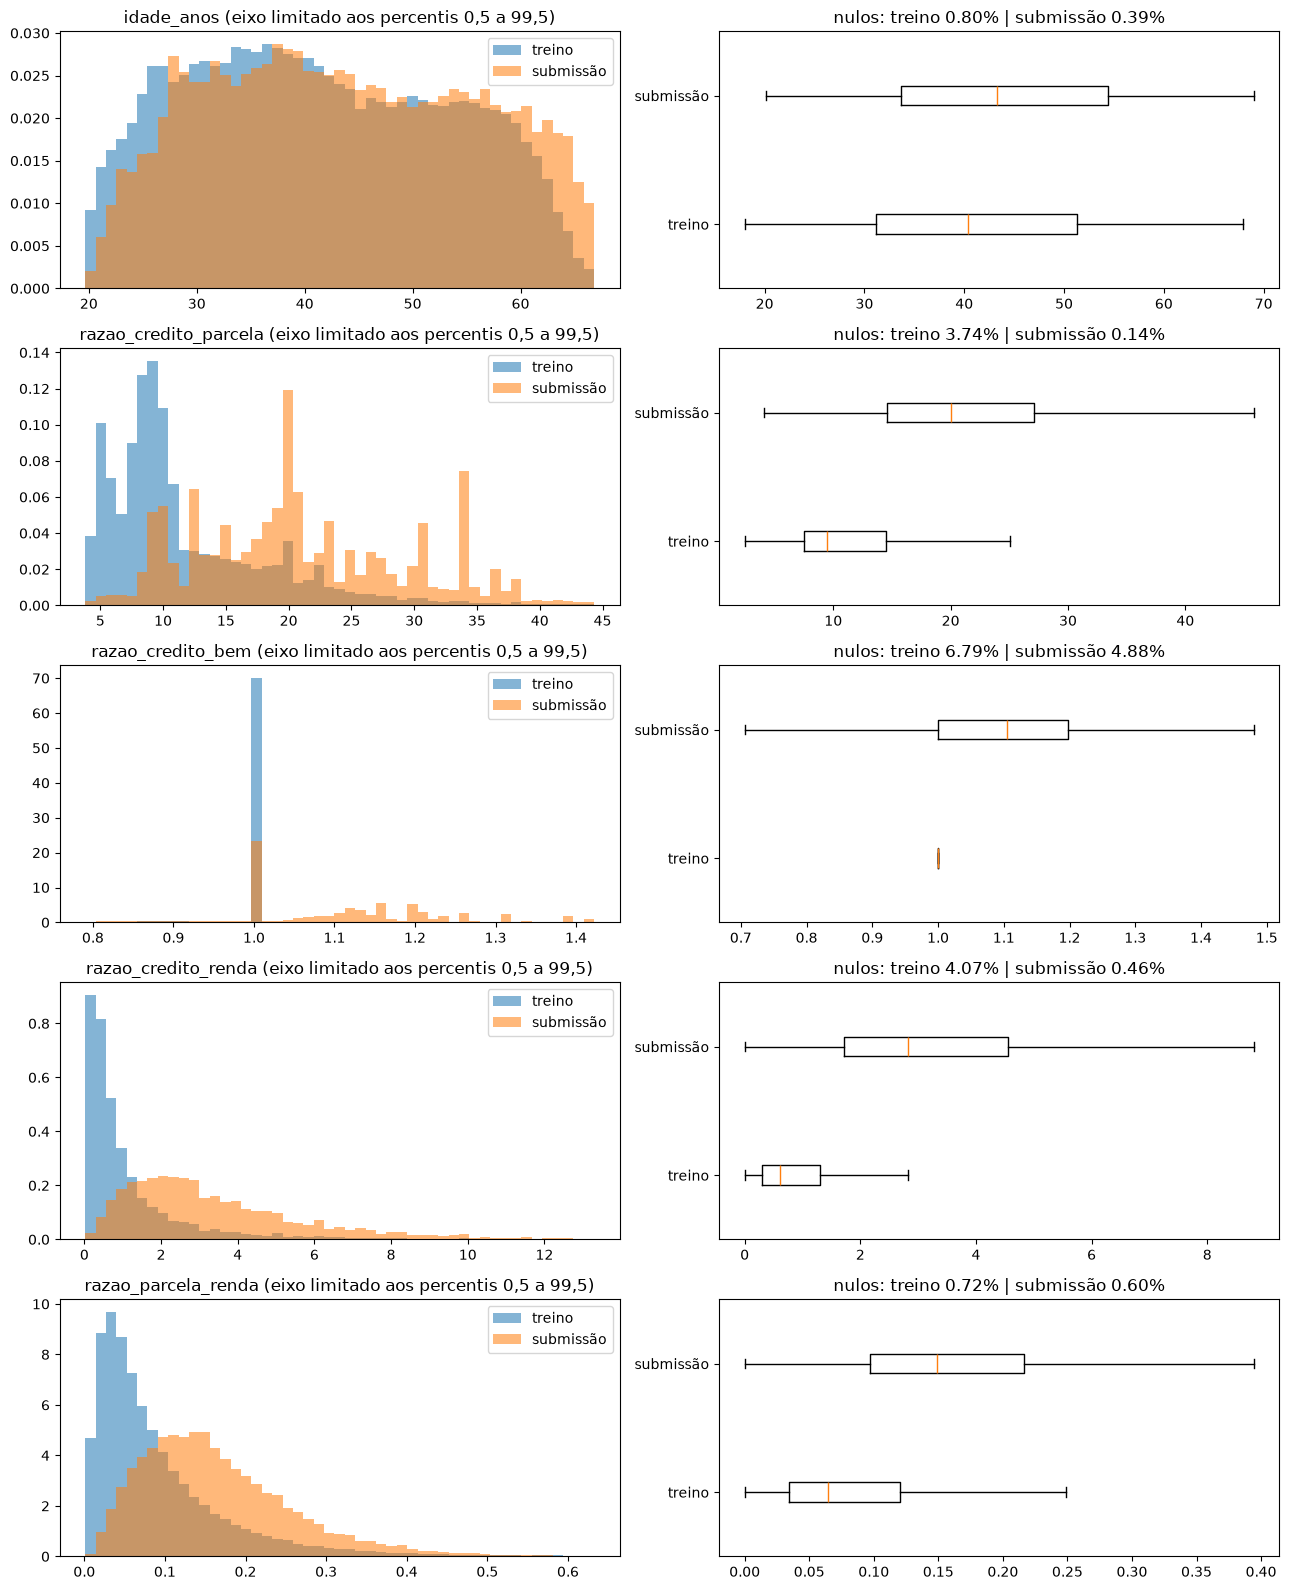

In [9]:
# ============================================================
# Grupo A (versão final) e gráficos treino vs submissão
# ============================================================
import matplotlib.pyplot as plt
importlib.reload(fn)

base_treino = fn.criar_features_grupo_a(base_treino)
base_submissao = fn.criar_features_grupo_a(base_submissao)

COLS_A = ["idade_anos", "razao_credito_parcela", "razao_credito_bem",
          "razao_credito_renda", "razao_parcela_renda"]

fig, eixos = plt.subplots(len(COLS_A), 2, figsize=(13, 3.2 * len(COLS_A)))
for i, col in enumerate(COLS_A):
    tr, sb = base_treino[col].dropna(), base_submissao[col].dropna()
    comb = pd.concat([tr, sb])
    lo, hi = comb.quantile(0.005), comb.quantile(0.995)
    bins = np.linspace(lo, hi, 50)

    # Esquerda: distribuições sobrepostas (densidade)
    ax = eixos[i, 0]
    ax.hist(tr, bins=bins, density=True, alpha=0.55, label="treino")
    ax.hist(sb, bins=bins, density=True, alpha=0.55, label="submissão")
    ax.set_title(f"{col} (eixo limitado aos percentis 0,5 a 99,5)")
    ax.legend()

    # Direita: boxplot sem outliers + percentual de nulos no título
    ax = eixos[i, 1]
    ax.boxplot([tr, sb], tick_labels=["treino", "submissão"], showfliers=False, orientation="horizontal")
    ax.set_title(f"nulos: treino {base_treino[col].isna().mean():.2%} | "
                 f"submissão {base_submissao[col].isna().mean():.2%}")

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# Faixas por quantis (bordas do treino) para idade e razões
# ============================================================
N_FAIXAS = 10
EPS = 1e-6
BORDAS = {col: fn.calcular_bordas_quantis(base_treino[col], N_FAIXAS) for col in COLS_A}

for col, b in BORDAS.items():
    base_treino[f"{col}_faixa"] = fn.aplicar_faixas(base_treino[col], b)
    base_submissao[f"{col}_faixa"] = fn.aplicar_faixas(base_submissao[col], b)

FEATURES_FAIXAS = [f"{col}_faixa" for col in COLS_A]

for col in COLS_A:
    f = f"{col}_faixa"
    print(f"\n{col} | bordas internas:", np.round(BORDAS[col][1:-1], 3))

    part_tr = base_treino[f].value_counts(normalize=True, dropna=False).sort_index()
    part_sb = base_submissao[f].value_counts(normalize=True, dropna=False).sort_index()
    tabela = pd.concat([part_tr.rename("pct_treino"), part_sb.rename("pct_submissao")], axis=1).fillna(0)

    maus = base_treino.groupby(f, dropna=False)[COL_TARGET].agg(taxa_maus="mean", n_rotulados="count")
    tabela = tabela.join(maus)

    p, q = tabela["pct_treino"].clip(lower=EPS), tabela["pct_submissao"].clip(lower=EPS)
    psi = float(((q - p) * np.log(q / p)).sum())
    display(tabela.round(4))
    print(f"PSI treino vs submissão: {psi:.4f}")


idade_anos | bordas internas: [25.325 29.306 33.125 36.701 40.356 44.383 48.986 53.596 58.278]


,pct_treino,pct_submissao,taxa_maus,n_rotulados
idade_anos_faixa,,,,
0.0,0.0992,0.0561,0.0882,10333
1.0,0.0992,0.0863,0.0689,10336
2.0,0.0992,0.0941,0.0674,10331
3.0,0.0992,0.0883,0.0683,10332
4.0,0.0992,0.0999,0.0638,10337
5.0,0.0992,0.1007,0.0658,10328
6.0,0.0992,0.1053,0.0719,10328
7.0,0.0992,0.0991,0.072,10335
8.0,0.0992,0.1042,0.0706,10330


PSI treino vs submissão: 0.0624

razao_credito_parcela | bordas internas: [ 5.249  6.708  7.992  8.773  9.494 10.415 12.663 16.594 21.047]


,pct_treino,pct_submissao,taxa_maus,n_rotulados
razao_credito_parcela_faixa,,,,
0.0,0.0963,0.0051,0.0636,10027
1.0,0.0963,0.0081,0.0657,10026
2.0,0.0963,0.0066,0.0725,10026
3.0,0.0963,0.0155,0.0669,10026
4.0,0.0964,0.0361,0.0649,10039
5.0,0.0961,0.0509,0.0634,10013
6.0,0.0963,0.0720,0.0681,10026
7.0,0.0964,0.1308,0.0742,10040
8.0,0.0962,0.2645,0.0796,10015


PSI treino vs submissão: 1.7197

razao_credito_bem | bordas internas: [1.]


,pct_treino,pct_submissao,taxa_maus,n_rotulados
razao_credito_bem_faixa,,,,
0.0,0.8888,0.3573,0.0632,92572
1.0,0.0433,0.5939,0.177,4513
NaN,0.0679,0.0488,0.112,7072


PSI treino vs submissão: 1.9320

razao_credito_renda | bordas internas: [0.154 0.244 0.34  0.463 0.609 0.803 1.102 1.6   2.795]


,pct_treino,pct_submissao,taxa_maus,n_rotulados
razao_credito_renda_faixa,,,,
0.0,0.0959,0.0014,0.1043,9993
1.0,0.0959,0.0023,0.0664,9993
2.0,0.0959,0.0062,0.0652,9991
3.0,0.0959,0.0090,0.0756,9992
4.0,0.0959,0.0161,0.0648,9992
5.0,0.0959,0.0290,0.0698,9992
6.0,0.0959,0.0535,0.0669,9992
7.0,0.0960,0.1063,0.07,9994
8.0,0.0959,0.2662,0.0671,9990


PSI treino vs submissão: 2.3837

razao_parcela_renda | bordas internas: [0.018 0.029 0.039 0.051 0.065 0.082 0.105 0.14  0.205]


,pct_treino,pct_submissao,taxa_maus,n_rotulados
razao_parcela_renda_faixa,,,,
0.0,0.0993,0.0045,0.1178,10342
1.0,0.0993,0.0136,0.068,10342
2.0,0.0993,0.0196,0.0691,10340
3.0,0.0993,0.0315,0.0627,10341
4.0,0.0993,0.0461,0.0665,10341
5.0,0.0993,0.0691,0.0643,10344
6.0,0.0993,0.1026,0.0637,10338
7.0,0.0993,0.1662,0.0632,10341
8.0,0.0993,0.2600,0.0627,10341


PSI treino vs submissão: 1.0998


In [11]:
# ============================================================
# Faixas de negócio para razao_credito_bem + gatilho da política
# ============================================================
LIM_RAZAO_CREDITO_BEM = 10            # política: recusa imediata acima deste valor
MAX_RAZAO_TREINO = float(base_treino["razao_credito_bem"].max())

BORDAS_CREDITO_BEM = [-np.inf, 0.995, 1.005, 1.2, MAX_RAZAO_TREINO,
                      LIM_RAZAO_CREDITO_BEM, np.inf]
ROTULOS_CREDITO_BEM = ["1_menor_1", "2_igual_1", "3_1_a_1.2",
                       "4_1.2_a_max_treino", "5_acima_suporte", "6_critica_gt_10"]

for df in (base_treino, base_submissao):
    # right=True: intervalos (a, b]; o primeiro inclui o limite inferior (-inf)
    df["razao_credito_bem_faixa"] = pd.cut(
        df["razao_credito_bem"], bins=BORDAS_CREDITO_BEM, labels=ROTULOS_CREDITO_BEM
    )
    # Gatilho da política derivado da própria faixa (explicável e auditável)
    df["politica_acionada"] = np.where(
        df["razao_credito_bem_faixa"] == "6_critica_gt_10",
        "recusa_razao_credito_bem_gt_10",
        "",
    )

# Tabela: participação, taxa de maus e concentração de maus, com PSI
agg = (
    base_treino.groupby("razao_credito_bem_faixa", observed=False, dropna=False)[COL_TARGET]
    .agg(n_rotulados="count", n_maus="sum", taxa_maus="mean")
)
agg["pct_maus_total"] = agg["n_maus"] / agg["n_maus"].sum()
agg["pct_treino"] = base_treino["razao_credito_bem_faixa"].value_counts(normalize=True, dropna=False)
agg["pct_submissao"] = base_submissao["razao_credito_bem_faixa"].value_counts(normalize=True, dropna=False)
agg = agg.fillna(0)
display(agg.round(4))

p = agg["pct_treino"].clip(lower=EPS)
q = agg["pct_submissao"].clip(lower=EPS)
print(f"PSI razao_credito_bem_faixa: {float(((q - p) * np.log(q / p)).sum()):.4f}")
print("Linhas com política acionada na submissão:",
      int((base_submissao["politica_acionada"] != "").sum()))

,n_rotulados,n_maus,taxa_maus,pct_maus_total,pct_treino,pct_submissao
razao_credito_bem_faixa,,,,,,
1_menor_1,5496,986,0.1794,0.1324,0.0528,0.0764
2_igual_1,87178,4884,0.056,0.6559,0.8370,0.2822
3_1_a_1.2,3363,597,0.1775,0.0802,0.0323,0.3932
4_1.2_a_max_treino,1048,187,0.1784,0.0251,0.0101,0.1526
5_acima_suporte,0,0,0.0,0.0,0.0000,0.0456
6_critica_gt_10,0,0,0.0,0.0,0.0000,0.0012
NaN,7072,792,0.112,0.1064,0.0679,0.0488


PSI razao_credito_bem_faixa: 2.4063
Linhas com política acionada na submissão: 63


In [15]:
base_treino.info()

<class 'pandas.DataFrame'>
Index: 104157 entries, 1 to 211939
Data columns (total 66 columns):
 #   Column                                 Non-Null Count   Dtype         
---  ------                                 --------------   -----         
 0   id_contrato                            104157 non-null  int64         
 1   id_cliente                             104157 non-null  int64         
 2   tipo_contrato                          104157 non-null  category      
 3   status_contrato                        104157 non-null  category      
 4   data_decisao                           104157 non-null  datetime64[us]
 5   data_liberacao                         5705 non-null    datetime64[us]
 6   data_primeiro_vencimento               104021 non-null  datetime64[us]
 7   data_ultimo_vencimento_original        98922 non-null   datetime64[us]
 8   data_ultimo_vencimento                 89847 non-null   datetime64[us]
 9   data_encerramento                      87963 non-null   datetime

## Registro de decisões até aqui

### Dados e referência temporal
- Bases processadas em `../dados/processados/`: `abt_completa`, `abt_submissao`, `abt_emprestimos`, `abt_parcelas` (Parquet, não versionados). Dados brutos em `../dados/` permanecem intactos.
- `data_ref` = `data_decisao` (treino) e `data_solicitacao` (submissão). Na submissão, 51 linhas (0,10%) têm `data_ref` nula, todas com `data_invalida = True`. Mantidas, com features dependentes de data nulas.
- Treino rotulado: 104.157 contratos. Sem rótulo: 107.787 (somente Reject Inference no treino).

### Baseline de referência (v2, 17 features disponíveis na submissão)
- Split OOT com corte 2023-06-06, embargo de 360 dias, walk-forward de 4 folds.
- Teste completo com embargo: AUC 0,556, KS 0,093. Sem embargo: AUC 0,568, KS 0,113.
- Walk-forward (folds 2 a 4): AUC 0,575, 0,612, 0,582. Fold 1 ignorado (poucos maus).
- O v1 (36 features) não é referência por usar atributos ausentes na submissão.

### Estratégia de modelagem
- Construir todas as variáveis (Grupo A, faixas, Grupo B), avaliar uma única vez contra o v2 e podar depois.
- Poda sem usar o teste OOT: importância por permutação nos folds do walk-forward, critério de estabilidade entre folds e agrupamento por correlação antes de descartar. O teste entra uma única vez, na comparação final.
- Faixas servem a explicabilidade e estabilidade (PSI); para árvores o ganho de AUC é esperado pequeno.

### Tratamentos do Grupo A
- Idade fora de [18, 100] vira nula (`flag_idade_inconsistente`): 653 no treino (76 negativas) e 75 na submissão (37 negativas).
- `valor_credito <= 0` no treino (3.729; 3,6%): distribuído nos três tipos de contrato, com parcela positiva; interpretado como valor ausente codificado como zero. Não ocorre na submissão. Vira nulo no cálculo, linhas mantidas, flag apenas diagnóstica.
- `valor_parcela <= 0`: 218 no treino (taxa de maus 6,9%) e 67 na submissão; mesmo padrão nos dois lados. Vira nulo, sem política.
- Colunas originais não são alteradas (preserva o baseline).
- Flags `flag_*` são diagnóstico e ficam fora das features.

### Mudança de distribuição treino vs submissão (achado central)
- PSI com faixas por quantis do treino: idade 0,06; razao_parcela_renda 1,10; razao_credito_parcela 1,72; razao_credito_bem 1,93; razao_credito_renda 2,38. Referência: <0,10 estável, 0,10 a 0,25 atenção, >0,25 mudança relevante.
- Na submissão, as razões crédito/renda, crédito/parcela e parcela/renda estão deslocadas para valores mais altos (mediana de crédito/renda 2,8 contra 0,6 no treino). Hipótese não verificada: mudança de portfólio (contratos maiores em relação à renda, prazos mais longos).
- razao_credito_bem: no treino é praticamente constante em 1,0 (88,9% das linhas na faixa até 1,0); na submissão há massa espalhada entre 1,05 e 1,45 (2.300 linhas acima do máximo do treino, 1,393), em razões exatas repetidas. Quantis do treino são inadequados; usar faixas de negócio.
- Consequência: as probabilidades da submissão podem sair descalibradas. Comparar a distribuição do score entre treino e submissão antes de interpretar.
- Idade: PSI estável; a faixa nula (idade inconsistente) tem taxa de maus de 14,1% contra 7,1% da média, então a flag de inconsistência é candidata a feature (existe nas duas bases).

### Faixas
- Idade: 10 faixas por quantis do treino. Razões: faixas por quantis do treino tornam o shift visível, mas não o corrigem. 
- Para `razao_credito_bem`:
    - 6 faixas de negócio + nulo: menor que 1, igual a 1 (0,995 a 1,005), 1 a 1,2, 1,2 até o máximo do treino (1,393), acima do suporte (1,393 a 10) e crítica (> 10).
    - A faixa crítica é vazia no treino e funciona como gatilho da política de recusa; a política é aplicada antes do modelo e registrada em `politica_acionada`, separada do score.
    - A faixa "acima do suporte" (4,6% da submissão) também não existe no treino: mantida separada para PSI e para análise à parte das probabilidades.
    - Taxa de maus nas faixas vazias no treino não é interpretável (sem dados).
    - Poda deve considerar remover variáveis com shift extremo mesmo que tenham sinal no treino.

### Políticas e monitoramento (a detalhar)
- Recusa imediata: razao_credito_bem > 10 (63 linhas), com pedido de revisão dos valores.
- O comportamento dos clientes muda de forma brusca: o modelo exige monitoramento mensal de PSI (variáveis e score), alerta acima de 0,10, revisão ou retreino acima de 0,25, acompanhamento da taxa de maus por safra madura (o target só amadurece em 360 dias) e recalibração como etapa intermediária.
- Com o PSI atual, o modelo nasce em estado de retreino necessário; as probabilidades são entregues com essa ressalva.

categóricas: ['tipo_contrato', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel']
categoria inédita em tipo_renda: 1 linhas


/tmp/ipykernel_43956/4294719403.py:13: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(X[c], categories=categorias[c])
/tmp/ipykernel_43956/4294719403.py:13: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(X[c], categories=categorias[c])
/tmp/ipykernel_43956/4294719403.py:13: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(X[c], categories=categorias[c])


,mean,5%,25%,50%,75%,95%,99%,max
treino (in-sample),0.0720,0.0402,0.0520,0.0593,0.0732,0.1588,0.2159,0.5599
teste OOT,0.0690,0.0414,0.0531,0.0603,0.0734,0.1358,0.1879,0.3912
submissao,0.0822,0.0430,0.0572,0.0697,0.0945,0.1644,0.2222,0.4772


Taxa observada de maus: treino 0.0718 | teste 0.0787
PSI do score, teste OOT vs treino (in-sample): 0.0319
{0: 0.111, 1: 0.1121, 2: 0.1079, 3: 0.102, 4: 0.0988, 5: 0.0928, 6: 0.0869, 7: 0.0785, 8: 0.0723, 9: 0.1379}
PSI do score, teste OOT vs submissao: 0.2106
{0: 0.0728, 1: 0.0639, 2: 0.0608, 3: 0.0583, 4: 0.0645, 5: 0.0799, 6: 0.0974, 7: 0.1222, 8: 0.1688, 9: 0.2113}


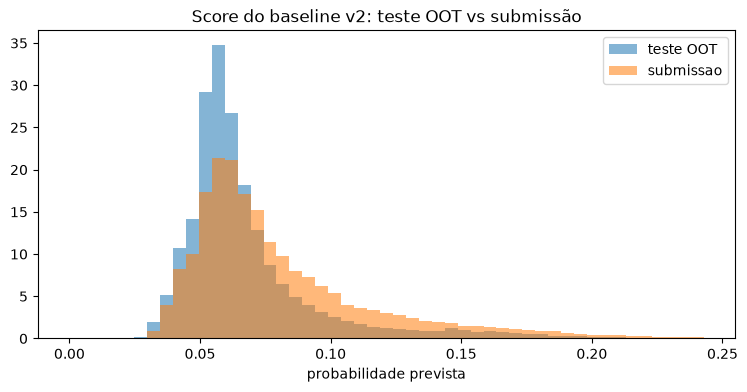

In [12]:
# ============================================================
# Distribuição do score (baseline v2): treino, teste OOT e submissão
# ============================================================
from sklearn.ensemble import HistGradientBoostingClassifier

colunas_cat = [c for c in FEATURES_V2 if tr_com[c].dtype == "object" or str(tr_com[c].dtype) in ("category", "string")]
print("categóricas:", colunas_cat)

def preparar_v2(df, categorias):
    """Mesmas categorias do treino; valores inéditos viram NaN. Não altera o df original."""
    X = df[FEATURES_V2].copy()
    for c in colunas_cat:
        X[c] = pd.Categorical(X[c], categories=categorias[c])
    return X

categorias_treino = {c: sorted(tr_com[c].dropna().unique()) for c in colunas_cat}
X_tr = preparar_v2(tr_com, categorias_treino)
X_te = preparar_v2(teste, categorias_treino)
X_sb = preparar_v2(base_submissao, categorias_treino)

for c in colunas_cat:
    inedito = base_submissao[c].notna() & ~base_submissao[c].isin(categorias_treino[c])
    if inedito.any():
        print(f"categoria inédita em {c}: {int(inedito.sum())} linhas")

modelo_v2 = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42)
modelo_v2.fit(X_tr, tr_com[COL_TARGET].astype(int))

score_tr = modelo_v2.predict_proba(X_tr)[:, 1]
score_te = modelo_v2.predict_proba(X_te)[:, 1]
score_sb = modelo_v2.predict_proba(X_sb)[:, 1]

SCORES = {"treino (in-sample)": score_tr, "teste OOT": score_te, "submissao": score_sb}
resumo = pd.DataFrame(
    {nome: pd.Series(s).describe(percentiles=[.05, .25, .5, .75, .95, .99]) for nome, s in SCORES.items()}
).T
display(resumo[["mean", "5%", "25%", "50%", "75%", "95%", "99%", "max"]].round(4))
print("Taxa observada de maus: treino", round(float(tr_com[COL_TARGET].mean()), 4),
      "| teste", round(float(teste[COL_TARGET].astype(float).mean()), 4))

# PSI do score: cortes por decis do score no teste OOT (sem target)
cortes = np.unique(np.quantile(score_te, np.linspace(0, 1, 11)[1:-1]))
bordas_score = np.concatenate(([-np.inf], cortes, [np.inf]))
n_faixas_score = len(bordas_score) - 1

def distribuicao_faixas(s):
    """Participação por faixa do score (Series com índice 0..n-1, sem zeros exatos)."""
    faixas = pd.Series(pd.cut(s, bins=bordas_score, labels=False))
    return faixas.value_counts(normalize=True).reindex(range(n_faixas_score), fill_value=0).clip(lower=EPS)

p = distribuicao_faixas(score_te)
for nome in ["treino (in-sample)", "submissao"]:
    q = distribuicao_faixas(SCORES[nome])
    psi = float(((q - p) * np.log(q / p)).sum())
    print(f"PSI do score, teste OOT vs {nome}: {psi:.4f}")
    print(q.round(4).to_dict())

# Gráfico: densidade do score por conjunto
plt.figure(figsize=(9, 4))
bins = np.linspace(0, np.quantile(np.concatenate([score_te, score_sb]), 0.995), 50)
for nome in ["teste OOT", "submissao"]:
    plt.hist(SCORES[nome], bins=bins, density=True, alpha=0.55, label=nome)
plt.title("Score do baseline v2: teste OOT vs submissão")
plt.xlabel("probabilidade prevista")
plt.legend()
plt.show()

In [17]:
## Grupo B - Variaveis historicas

In [16]:
abt_emp = pd.read_parquet("../dados/processados/abt_emprestimos.parquet")
abt_par = pd.read_parquet("../dados/processados/abt_parcelas.parquet")

for nome, df in {"abt_emprestimos": abt_emp, "abt_parcelas": abt_par}.items():
    print(f"\n{nome}: {df.shape}")
    print(df.dtypes.to_string())

print("\nColunas de base_submissao:", list(base_submissao.columns))
print("\nParcelas (amostra):")
display(abt_par.head(5))


abt_emprestimos: (211944, 35)
id_contrato                                       int64
id_cliente                                        int64
tipo_contrato                                  category
status_contrato                                category
data_decisao                             datetime64[us]
data_liberacao                           datetime64[us]
data_primeiro_vencimento                 datetime64[us]
data_ultimo_vencimento_original          datetime64[us]
data_ultimo_vencimento                   datetime64[us]
data_encerramento                        datetime64[us]
valor_credito                                   float64
valor_credito_concedido                         float64
valor_bem                                       float64
valor_parcela                                   float64
valor_entrada                                   float64
percentual_entrada                              float64
qtd_parcelas_planejadas                           Int64
taxa_juros_padrao

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0,56,2021-12-21,2021-12-21,301.86,301.86
1,1995642,134723,1,38,2021-08-09,2021-08-04,12949.20,12949.20
2,1720935,176364,1,9,2024-03-06,2024-03-04,61192.53,61192.53
3,1439208,154898,1,20,2024-08-11,2024-08-07,8851.23,8851.23
4,1640082,172575,1,4,2022-11-15,2022-11-10,8720.28,8720.28


In [18]:
# ============================================================
# Grupo B | Célula 1: parâmetros, carga e checagens
# ============================================================
JANELAS_DIAS = (90, 180, 360, 720)     # dias antes de data_ref
LIMITES_ATRASO = (30, 60, 90)          # dias de atraso
TOL_PAGO_MENOR = 0.01                  # tolerância para "pago a menos"
DIAS_MES = 30.4375
MIN_MESES_REL = 1                      # piso para evitar razões explosivas
STATUS_APROVADO = "aprovado"

abt_emp = pd.read_parquet("../dados/processados/abt_emprestimos.parquet")
abt_par = pd.read_parquet("../dados/processados/abt_parcelas.parquet")

base_submissao["chave"] = np.arange(len(base_submissao))
BASES_B = {
    "completa": (base_completa, "id_contrato"),
    "submissao": (base_submissao, "chave"),
}

print("status_contrato:\n", abt_emp["status_contrato"].value_counts(dropna=False))
print("\nSubmissão: clientes com contrato em abt_emprestimos:",
      round(float(base_submissao["id_cliente"].isin(abt_emp["id_cliente"]).mean()), 4))
print("Último pagamento real em abt_parcelas:", abt_par["data_real_pagamento"].max())
print("data_ref da submissão (min, max):",
      base_submissao["data_ref"].min(), base_submissao["data_ref"].max())

# Versões de parcela: mantém a maior versão por (contrato, número)
n_dup = int(abt_par.duplicated(["id_contrato", "numero_parcela"]).sum())
print("Parcelas duplicadas por (id_contrato, numero_parcela):", n_dup)
abt_par = (abt_par.sort_values("versao_parcela")
           .drop_duplicates(["id_contrato", "numero_parcela"], keep="last")
           .reset_index(drop=True))

# Base de parcelas com a data de decisão do contrato de origem (usada no corte por data_ref)
datas_contrato = abt_emp[["id_contrato", "data_decisao"]].rename(
    columns={"id_contrato": "id_hist", "data_decisao": "data_hist"})
par_h = (abt_par[["id_contrato", "id_cliente", "data_prevista_pagamento", "data_real_pagamento",
                  "valor_previsto_parcela", "valor_pago_parcela"]]
         .rename(columns={"id_contrato": "id_hist"})
         .merge(datas_contrato, on="id_hist", how="left"))
print("Parcelas sem data_decisao do contrato:", int(par_h["data_hist"].isna().sum()))

status_contrato:
 status_contrato
aprovado                131735
cancelado                40266
recusado                 36359
oferta nao utilizada      3584
Name: count, dtype: int64

Submissão: clientes com contrato em abt_emprestimos: 0.9591
Último pagamento real em abt_parcelas: 2025-02-22 00:00:00
data_ref da submissão (min, max): 2025-02-04 00:00:00 2025-02-24 00:00:00
Parcelas duplicadas por (id_contrato, numero_parcela): 84997
Parcelas sem data_decisao do contrato: 0


In [19]:
# ============================================================
# Grupo B | Célula 2: histórico de contratos (B1)
# Regra anti-vazamento: só contratos com data_decisao < data_ref (estrito)
# ============================================================
hist = abt_emp[["id_contrato", "id_cliente", "data_decisao", "status_contrato", "valor_credito"]].rename(
    columns={"id_contrato": "id_hist", "data_decisao": "data_hist", "valor_credito": "credito_hist"})

fb_contratos = {}
for nome, (base, chave) in BASES_B.items():
    if not base[chave].is_unique:
        raise ValueError(f"{chave} precisa ser única em {nome}.")

    pares = base[[chave, "id_cliente", "data_ref"]].merge(hist, on="id_cliente", how="inner")
    pares = pares.loc[pares["data_hist"] < pares["data_ref"]].copy()
    pares["dias_atras"] = (pares["data_ref"] - pares["data_hist"]).dt.days

    aprovado = (pares["status_contrato"] == STATUS_APROVADO)
    credito_aprov = pares["credito_hist"].where((pares["credito_hist"] > 0) & aprovado)

    novas, agg = {}, {}
    for w in [*JANELAS_DIAS, None]:
        suf = "total" if w is None else f"{w}d"
        dentro = pd.Series(True, index=pares.index) if w is None else pares["dias_atras"].le(w)
        novas[f"_qtd_{suf}"] = dentro.astype("int8")
        novas[f"_apr_{suf}"] = (dentro & aprovado).astype("int8")
        novas[f"_cred_{suf}"] = credito_aprov.where(dentro)
        agg[f"qtd_contratos_{suf}"] = (f"_qtd_{suf}", "sum")
        agg[f"qtd_aprovados_{suf}"] = (f"_apr_{suf}", "sum")
        agg[f"credito_medio_{suf}"] = (f"_cred_{suf}", "mean")
        agg[f"credito_max_{suf}"] = (f"_cred_{suf}", "max")
    agg["dias_desde_ultimo_contrato"] = ("dias_atras", "min")
    agg["dias_desde_primeiro_contrato"] = ("dias_atras", "max")

    feats = pares.assign(**novas).groupby(chave).agg(**agg).reindex(base[chave].to_numpy())

    for w in [*JANELAS_DIAS, None]:
        suf = "total" if w is None else f"{w}d"
        feats[f"qtd_nao_aprovados_{suf}"] = feats[f"qtd_contratos_{suf}"] - feats[f"qtd_aprovados_{suf}"]

    cols_qtd = [c for c in feats.columns if c.startswith("qtd_")]
    feats[cols_qtd] = feats[cols_qtd].fillna(0)

    # Crédito atual contra histórico
    atual_s = base.set_index(chave)["valor_credito"]
    atual = atual_s.where(atual_s > 0)
    for suf in (f"{JANELAS_DIAS[-1]}d", "total"):
        feats[f"razao_credito_atual_max_{suf}"] = atual / feats[f"credito_max_{suf}"]
        feats[f"razao_credito_atual_media_{suf}"] = atual / feats[f"credito_medio_{suf}"]

    # Tempo de relacionamento (meses), com piso
    feats["meses_relacionamento"] = (feats["dias_desde_primeiro_contrato"] / DIAS_MES).clip(lower=MIN_MESES_REL)

    feats = feats.astype("float32")
    feats.loc[base["data_ref"].isna().to_numpy(), :] = np.nan
    fb_contratos[nome] = feats
    print(nome, "-> B1:", feats.shape)

completa -> B1: (211944, 32)
submissao -> B1: (50400, 32)


In [20]:
# ============================================================
# Grupo B | Célula 3: comportamento de pagamento (B2)
# Regras (tudo medido em data_ref):
#  - contratos com data_decisao < data_ref
#  - parcelas com data_prevista_pagamento <= data_ref
#  - pagamento só conta se data_real_pagamento <= data_ref; senão está em aberto
#    e o atraso é medido até data_ref
# ============================================================
fb_parcelas = {}
for nome, (base, chave) in BASES_B.items():
    pares = base[[chave, "id_cliente", "data_ref"]].merge(par_h, on="id_cliente", how="inner")
    elegivel = (pares["data_hist"] < pares["data_ref"]) & (pares["data_prevista_pagamento"] <= pares["data_ref"])
    pares = pares.loc[elegivel].copy()

    pago = pares["data_real_pagamento"].notna() & (pares["data_real_pagamento"] <= pares["data_ref"])
    data_efetiva = pares["data_real_pagamento"].where(pago, pares["data_ref"])
    atraso = (data_efetiva - pares["data_prevista_pagamento"]).dt.days.clip(lower=0)
    pago_menor = pago & (pares["valor_pago_parcela"] < pares["valor_previsto_parcela"] * (1 - TOL_PAGO_MENOR))
    dias_venc = (pares["data_ref"] - pares["data_prevista_pagamento"]).dt.days

    novas, agg = {}, {}
    for w in [*JANELAS_DIAS, None]:
        suf = "total" if w is None else f"{w}d"
        dentro = pd.Series(True, index=pares.index) if w is None else dias_venc.le(w)

        novas[f"_n_{suf}"] = dentro.astype("int8")
        novas[f"_atr_{suf}"] = (dentro & (atraso > 0)).astype("int8")
        novas[f"_abe_{suf}"] = (dentro & ~pago).astype("int8")
        novas[f"_men_{suf}"] = (dentro & pago_menor).astype("int8")
        novas[f"_dias_{suf}"] = atraso.where(dentro)
        agg[f"qtd_parc_vencidas_{suf}"] = (f"_n_{suf}", "sum")
        agg[f"qtd_parc_atrasadas_{suf}"] = (f"_atr_{suf}", "sum")
        agg[f"qtd_parc_em_aberto_{suf}"] = (f"_abe_{suf}", "sum")
        agg[f"qtd_parc_pagas_a_menos_{suf}"] = (f"_men_{suf}", "sum")
        agg[f"atraso_medio_{suf}"] = (f"_dias_{suf}", "mean")
        agg[f"atraso_max_{suf}"] = (f"_dias_{suf}", "max")
        agg[f"dias_atraso_acum_{suf}"] = (f"_dias_{suf}", "sum")      # soma de todos os atrasos
        for lim in LIMITES_ATRASO:
            novas[f"_gt{lim}_{suf}"] = (dentro & (atraso > lim)).astype("int8")
            agg[f"qtd_parc_atraso_gt{lim}_{suf}"] = (f"_gt{lim}_{suf}", "sum")

    # Contratos executados: contratos anteriores com ao menos uma parcela vencida até data_ref
    qtd_exec = (pares[[chave, "id_hist"]].drop_duplicates().groupby(chave).size()
                .rename("qtd_contratos_executados"))

    feats = (pares.assign(**novas).groupby(chave).agg(**agg)
             .join(qtd_exec).reindex(base[chave].to_numpy()))

    cols_qtd = [c for c in feats.columns if c.startswith("qtd_")]
    feats[cols_qtd] = feats[cols_qtd].fillna(0)
    feats["dias_atraso_acum_total"] = feats["dias_atraso_acum_total"]  # NaN = sem parcela vencida

    # Proporções sobre as parcelas vencidas (denominador 0 -> NaN)
    props = {}
    for w in [*JANELAS_DIAS, None]:
        suf = "total" if w is None else f"{w}d"
        venc = feats[f"qtd_parc_vencidas_{suf}"].where(feats[f"qtd_parc_vencidas_{suf}"] > 0)
        props[f"pct_parc_atrasadas_{suf}"] = feats[f"qtd_parc_atrasadas_{suf}"] / venc
        props[f"pct_parc_em_aberto_{suf}"] = feats[f"qtd_parc_em_aberto_{suf}"] / venc
        props[f"pct_parc_pagas_a_menos_{suf}"] = feats[f"qtd_parc_pagas_a_menos_{suf}"] / venc
        for lim in LIMITES_ATRASO:
            props[f"pct_parc_atraso_gt{lim}_{suf}"] = feats[f"qtd_parc_atraso_gt{lim}_{suf}"] / venc

    # Parcelas atrasadas por contrato executado
    exec_ = feats["qtd_contratos_executados"].where(feats["qtd_contratos_executados"] > 0)
    props["parc_atrasadas_por_contrato_exec"] = feats["qtd_parc_atrasadas_total"] / exec_
    props["parc_gt90_por_contrato_exec"] = feats["qtd_parc_atraso_gt90_total"] / exec_

    feats = pd.concat([feats, pd.DataFrame(props, index=feats.index)], axis=1).astype("float32")
    feats.loc[base["data_ref"].isna().to_numpy(), :] = np.nan
    fb_parcelas[nome] = feats
    print(nome, "-> B2:", feats.shape)

completa -> B2: (211944, 83)
submissao -> B2: (50400, 83)


In [21]:
# ============================================================
# Grupo B | Célula 4: razões por tempo de relacionamento e anexação às bases
# ============================================================
fb = {}
for nome in BASES_B:
    f = pd.concat([fb_contratos[nome], fb_parcelas[nome]], axis=1)

    meses_rel = f["meses_relacionamento"]          # NaN se não há contrato anterior
    f["meses_atraso_acum_total"] = f["dias_atraso_acum_total"] / DIAS_MES
    f["meses_atraso_acum_por_mes_rel"] = f["meses_atraso_acum_total"] / meses_rel
    f["parc_atraso_gt90_por_mes_rel"] = f["qtd_parc_atraso_gt90_total"] / meses_rel
    f["parc_atrasadas_por_mes_rel"] = f["qtd_parc_atrasadas_total"] / meses_rel
    f["parc_gt30_por_mes_rel"] = f["qtd_parc_atraso_gt30_total"] / meses_rel

    fb[nome] = f.astype("float32")

COLS_B = list(fb["completa"].columns)
print("Features do Grupo B:", len(COLS_B))

def anexar(df, feats, chave):
    """Anexa feats a df pela chave, preservando índice e ordem (remove versão anterior)."""
    df = df.drop(columns=COLS_B, errors="ignore")
    tmp = feats.reindex(df[chave].to_numpy())
    tmp.index = df.index
    return pd.concat([df, tmp], axis=1)

base_treino = anexar(base_treino, fb["completa"], "id_contrato")
base_sem_rotulo = anexar(base_sem_rotulo, fb["completa"], "id_contrato")
base_submissao = anexar(base_submissao, fb["submissao"], "chave")

Features do Grupo B: 120


In [22]:
# ============================================================
# Grupo B | Célula 5: cobertura e shift treino vs submissão
# ============================================================
for nome, df in {"treino": base_treino, "submissao": base_submissao}.items():
    print(f"{nome}: sem contrato anterior {(df['qtd_contratos_total'] == 0).mean():.2%} | "
          f"sem parcela vencida {(df['qtd_parc_vencidas_total'] == 0).mean():.2%}")

NOVAS_VARS = ["dias_atraso_acum_total", "meses_atraso_acum_por_mes_rel", "parc_atraso_gt90_por_mes_rel",
              "parc_atrasadas_por_mes_rel", "parc_atrasadas_por_contrato_exec",
              "meses_relacionamento", "qtd_parc_atraso_gt90_total", "qtd_contratos_executados"]
resumo = pd.concat(
    {nome: df[NOVAS_VARS].describe(percentiles=[.5, .95, .99]).T[["count", "mean", "50%", "95%", "99%", "max"]]
     for nome, df in {"treino": base_treino, "submissao": base_submissao}.items()},
    axis=1,
)
display(resumo.round(3))

# Nulos por variável: treino vs submissão (cobertura diferente indica shift)
nulos = pd.DataFrame({
    "nulos_treino": base_treino[COLS_B].isna().mean(),
    "nulos_submissao": base_submissao[COLS_B].isna().mean(),
})
nulos["dif"] = (nulos["nulos_submissao"] - nulos["nulos_treino"]).abs()
display(nulos.sort_values("dif", ascending=False).head(15).round(4))

treino: sem contrato anterior 38.82% | sem parcela vencida 41.83%
submissao: sem contrato anterior 4.12% | sem parcela vencida 7.59%


treino                                     \
                                     count    mean     50%      95%       99%   
dias_atraso_acum_total             60587.0  55.812   1.000  189.000  1180.420   
meses_atraso_acum_por_mes_rel      60587.0   0.048   0.001    0.225     0.852   
parc_atraso_gt90_por_mes_rel       63725.0   0.002   0.000    0.015     0.047   
parc_atrasadas_por_mes_rel         63725.0   0.073   0.000    0.350     0.591   
parc_atrasadas_por_contrato_exec   60587.0   1.238   0.250    6.000    11.000   
meses_relacionamento               63725.0  32.470  29.273   69.454    77.733   
qtd_parc_atraso_gt90_total        104157.0   0.040   0.000    0.000     1.000   
qtd_contratos_executados          104157.0   1.303   1.000    5.000     7.000   

                                            submissao                   \
                                        max     count     mean     50%   
dias_atraso_acum_total            39556.000   46526.0  123.154  12.000   
meses_atraso_acum_por_mes_rel        17.534   46526.0    0.075   0.008   
parc_atraso_gt90_por_mes_rel          0.651   48273.0    0.004   0.000   
parc_atrasadas_por_mes_rel            1.199   48273.0    0.081   0.030   
parc_atrasadas_por_contrato_exec     37.000   46526.0    1.986   0.600   
meses_relacionamento                 84.238   48273.0   51.705  52.928   
qtd_parc_atraso_gt90_total           48.000   50349.0    0.133   0.000   
qtd_contratos_executados             21.000   50349.0    2.454   2.000   

                                                                
                                      95%       99%        max  
dias_atraso_acum_total            487.750  2077.750  39633.000  
meses_atraso_acum_por_mes_rel       0.415     0.951     14.145  
parc_atraso_gt90_por_mes_rel        0.022     0.067      0.634  
parc_atrasadas_por_mes_rel          0.340     0.534      1.453  
parc_atrasadas_por_contrato_exec    9.000    12.000     64.000  
meses_relacionamento               91.959    95.212     96.000  
qtd_parc_atraso_gt90_total          1.000     1.000     55.000  
qtd_contratos_executados            6.000     9.000     23.000

,nulos_treino,nulos_submissao,dif
razao_credito_atual_max_total,0.4474,0.0771,0.3703
razao_credito_atual_media_total,0.4474,0.0771,0.3703
dias_desde_primeiro_contrato,0.3882,0.0422,0.3460
dias_desde_ultimo_contrato,0.3882,0.0422,0.3460
meses_relacionamento,0.3882,0.0422,0.3460
parc_atraso_gt90_por_mes_rel,0.3882,0.0422,0.3460
parc_gt30_por_mes_rel,0.3882,0.0422,0.3460
parc_atrasadas_por_mes_rel,0.3882,0.0422,0.3460
credito_medio_total,0.4188,0.0771,0.3417
credito_max_total,0.4188,0.0771,0.3417


## Variáveis criadas: Grupos A e B

### Grupo A (contrato atual e cadastro)
- `idade_anos`: (data_ref - data_nascimento) / 365,25; fora de [18, 100] vira nula (`flag_idade_inconsistente`).
- `razao_credito_parcela`, `razao_credito_bem`, `razao_credito_renda`, `razao_parcela_renda`: divisões com denominador válido (> 0); valor ausente ou <= 0 vira nulo.
- `flag_credito_zero`, `flag_parcela_zero`: diagnóstico, fora das features.
- `*_faixa`: idade e razões em 10 faixas por quantis do treino; `razao_credito_bem_faixa` em 6 faixas de negócio (menor que 1, igual a 1, 1 a 1,2, 1,2 até o máximo do treino, acima do suporte, crítica > 10).
- `politica_acionada`: recusa quando `razao_credito_bem` > 10; coluna separada do score.

### Grupo B (histórico do cliente, só informação anterior a `data_ref`)
Janelas: 90, 180, 360 e 720 dias antes de `data_ref`, mais o total (sufixos `_90d`, `_180d`, `_360d`, `_720d`, `_total`).

Contratos anteriores (`data_decisao` < `data_ref`):
- `qtd_contratos_*`, `qtd_aprovados_*`, `qtd_nao_aprovados_*`: contagem de contratos anteriores, aprovados e não aprovados (recusado, cancelado, oferta não utilizada).
- `credito_medio_*`, `credito_max_*`: crédito médio e máximo dos aprovados anteriores.
- `dias_desde_ultimo_contrato`, `dias_desde_primeiro_contrato`, `meses_relacionamento`: tempo desde o último e o primeiro contrato (meses de 30,4375 dias, piso de 1).
- `razao_credito_atual_max_*`, `razao_credito_atual_media_*` (720d e total): crédito atual dividido pelo máximo e pela média anteriores.

Parcelas dos contratos anteriores (vencidas até `data_ref`; pagamento só conta se feito até `data_ref`, senão fica em aberto com atraso medido até `data_ref`; maior `versao_parcela` por contrato e número):
- `qtd_parc_vencidas_*`, `qtd_parc_atrasadas_*`, `qtd_parc_em_aberto_*`, `qtd_parc_pagas_a_menos_*`.
- `qtd_parc_atraso_gt30_*`, `_gt60_*`, `_gt90_*`: parcelas com atraso acima de 30, 60 e 90 dias.
- `atraso_medio_*`, `atraso_max_*`, `dias_atraso_acum_*`: média, máximo e soma dos dias de atraso.
- `pct_parc_atrasadas_*`, `pct_parc_em_aberto_*`, `pct_parc_pagas_a_menos_*`, `pct_parc_atraso_gt30_*`, `_gt60_*`, `_gt90_*`: proporções sobre as parcelas vencidas.
- `qtd_contratos_executados`: contratos anteriores com ao menos uma parcela vencida.
- `parc_atrasadas_por_contrato_exec`, `parc_gt90_por_contrato_exec`: parcelas atrasadas (e com atraso > 90 dias) por contrato executado.

Razões por tempo de relacionamento:
- `meses_atraso_acum_total`, `meses_atraso_acum_por_mes_rel`, `parc_atrasadas_por_mes_rel`, `parc_gt30_por_mes_rel`, `parc_atraso_gt90_por_mes_rel`.

Convenções: contagens sem histórico = 0; médias, razões e proporções sem denominador = nulo; linhas com `data_ref` nula ficam com todo o Grupo B nulo. Total de 120 variáveis no Grupo B.

### Observações
- Cobertura de histórico diferente: sem contrato anterior em 38,8% do treino e 4,1% da submissão; a submissão é quase toda de clientes recorrentes.
- Variáveis de acúmulo (`*_total`, `meses_relacionamento`, `dias_atraso_acum_*`) sofrem censura à esquerda e estão deslocadas na submissão (mediana de relacionamento: 29 meses no treino, 53 na submissão). Tratar como suspeitas de proxy de tempo na poda.
- Janelas fixas e razões normalizadas são as candidatas mais comparáveis entre as bases.
- 84.997 parcelas duplicadas removidas mantendo a maior versão; premissa a validar (risco de a versão ser posterior à `data_ref`).
- Avaliar o ganho principalmente no recorte de clientes recorrentes, que representa a submissão.